# Notebook 05 — PWA evaluation and exploratory fine-tuning

**Project:** SkinX — AI-assisted early screening of skin cancer in people with albinism in Rwanda.

**Goal:** Test the **locked conventional EfficientNetB0 model** on our separately collected PWA clinical images, then explore whether carefully limited PWA adaptation changes performance.

**We keep the original model and threshold unchanged.** The locked model uses 224 × 224 RGB images, aspect-ratio-preserving padding, and pixel values from 0–255. Preprocessing is already built into the saved Keras model.

**Two parts:**
1. **Direct PWA evaluation:** Evaluate the original model on all available PWA images without training or threshold changes.
2. **Exploratory PWA adaptation:** Use **source-group-held-out, two-fold** comparisons. In each fold, train a *new copy* of the classifier head using only the fold's PWA training cases plus replay images from Notebook 02's conventional **training** split. Compare the adapted model against the unchanged model on exactly the same held-out PWA cases.

**Important limitations (dataset checked on 22 October 2026):** The PWA folder has **33 images**: 15 SCC, 11 BCC, 2 melanoma, 3 nevi, and 2 atypical nevi; only **5 NON_TARGET** images, from **2 source groups**. It has **no AK images**. All 33 are marked as source-reported/provisional, not independently dermatologist-confirmed. Several images are from the same published case or source. These are **pilot research results only**, not a validated clinical performance estimate. A source-group split avoids obvious source reuse, but cannot establish fully independent patients or eliminate publication bias.

**Do not choose new thresholds, epochs, or architectures after seeing the PWA holdout results.** We use the threshold locked in Notebook 04 for both models. The adapted fold models are *not* a new final deployable model.

## 1. Connect Colab and set the experiment

Run in **Google Colab** (a GPU is helpful for the adaptation part). Data and saved models stay in Google Drive. Change `RUN_TAG` only when starting a genuinely new run; the notebook will never silently overwrite old results.

In [3]:
from google.colab import drive
from pathlib import Path
import gc
import hashlib
import json
import math
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from PIL import Image
from sklearn.metrics import (
    confusion_matrix, roc_auc_score, average_precision_score,
    ConfusionMatrixDisplay
)
from IPython.display import display

drive.mount("/content/drive")

PROJECT_ROOT = Path("/content/drive/MyDrive/SkinX")
PWA_ROOT = PROJECT_ROOT / "data/raw_data/PWA_clinical_images"
METADATA_PATH = PWA_ROOT / "metadata.csv"
LOCKED_RUN = PROJECT_ROOT / "models/runs/notebook_04/three_models_finetune_v1"
LOCK_PATH = LOCKED_RUN / "locked_selection.json"
TRAIN_PATH = PROJECT_ROOT / "data/splits/skinX_train_manifest_v1.csv"

RUN_TAG = "pwa_grouped_v1"
RUN_DIR = PROJECT_ROOT / "models/runs/notebook_05" / RUN_TAG

SEED = 42
IMG_SIZE = (224, 224)
BATCH_SIZE = 16

# Small pilot experiment — pre-set these BEFORE inspecting results.
RUN_ADAPTATION = True
ADAPT_EPOCHS = 6
ADAPT_LEARNING_RATE = 5e-5
PWA_SAMPLE_WEIGHT = 6.0
REPLAY_PER_CLASS = 80   # conventional TRAIN images from each class, not VAL/TEST

tf.keras.utils.set_random_seed(SEED)
print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))
print("PWA folder:", PWA_ROOT)
print("Outputs:", RUN_DIR)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
TensorFlow: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
PWA folder: /content/drive/MyDrive/SkinX/data/raw_data/PWA_clinical_images
Outputs: /content/drive/MyDrive/SkinX/models/runs/notebook_05/pwa_grouped_v1


## 2. Read the PWA metadata and check the images

The CSV's `filepath` values are relative to `MyDrive/SkinX/data/raw_data/PWA_clinical_images`. We **do not** guess labels from folder names; we check the diagnosis, binary label, evidence field, and source grouping recorded in the CSV. Existing crops are used as provided — no new cropping or augmentation is applied during evaluation.

In [4]:
def sha256_file(path):
    digest = hashlib.sha256()
    with open(path, "rb") as stream:
        for chunk in iter(lambda: stream.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()


def md5_file(path):
    digest = hashlib.md5()
    with open(path, "rb") as stream:
        for chunk in iter(lambda: stream.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()


required = [
    "image_id", "filepath", "diagnosis", "diagnostic", "label_group",
    "binary_label", "label_status", "albinism_evidence", "modality",
    "focal_lesion", "source_id", "source_group_id", "split_group_id", "sha256"
]
if not METADATA_PATH.is_file():
    raise FileNotFoundError(f"Missing PWA metadata: {METADATA_PATH}")

pwa = pd.read_csv(METADATA_PATH, keep_default_na=False)
missing_cols = sorted(set(required) - set(pwa.columns))
if missing_cols:
    raise ValueError(f"PWA metadata is missing: {missing_cols}")
if pwa.empty or pwa[required].astype(str).eq("").any().any():
    raise ValueError("PWA metadata has missing required values")
if pwa["image_id"].duplicated().any() or pwa["sha256"].duplicated().any():
    raise ValueError("Duplicate PWA image IDs or SHA256 hashes detected")
if not pwa["binary_label"].isin([0, 1]).all():
    raise ValueError("Only binary labels 0 and 1 are supported")
if not (pwa["binary_label"] == pwa["label_group"].map({"TARGET": 1, "NON_TARGET": 0})).all():
    raise ValueError("The label_group and binary_label columns disagree")
if not pwa["modality"].eq("clinical_photo").all():
    raise ValueError("Some images are not recorded as clinical photographs")
if not pwa["focal_lesion"].astype(str).str.lower().eq("true").all():
    raise ValueError("Some records are not marked as focal lesions")
if pwa["split_group_id"].astype(str).str.strip().eq("").any():
    raise ValueError("Every PWA image needs a conservative split_group_id")

# Resolve only paths underneath PWA_ROOT to prevent accidental use of other folders.
root_resolved = PWA_ROOT.resolve()
resolved = []
for rel in pwa["filepath"].astype(str):
    candidate = (PWA_ROOT / rel).resolve()
    if not candidate.is_relative_to(root_resolved):
        raise ValueError(f"Image path escapes PWA folder: {rel}")
    if not candidate.is_file():
        raise FileNotFoundError(f"Missing PWA image: {candidate}")
    resolved.append(str(candidate))
pwa["absolute_path"] = resolved

bad = []
for row in pwa.itertuples(index=False):
    path = Path(row.absolute_path)
    try:
        with Image.open(path) as im:
            if im.format not in {"JPEG", "PNG"} or im.width < 64 or im.height < 64:
                bad.append((row.image_id, "invalid or very small image"))
            if "image_width" in pwa.columns and (im.width != int(row.image_width) or im.height != int(row.image_height)):
                bad.append((row.image_id, "dimensions differ from metadata"))
    except Exception as exc:
        bad.append((row.image_id, str(exc)))
    if sha256_file(path).lower() != str(row.sha256).lower():
        bad.append((row.image_id, "SHA256 mismatch"))
if bad:
    raise ValueError(f"PWA dataset verification failed: {bad[:10]}")

print("Verified images:", len(pwa))
print("Unique split groups:", pwa["split_group_id"].nunique())
print("Provisional label status:")
display(pwa["label_status"].value_counts().rename_axis("label_status").to_frame("images"))
display(pd.crosstab(pwa["diagnosis"], pwa["label_group"], margins=True))
display(pwa.groupby("source_group_id")["image_id"].count().rename("images").to_frame())

print("NOTE: Source-reported diagnoses are not the same as dermatologist review of each image.")
print("NOTE: Small images and multi-lesion panels may limit what the model can recognize.")

Verified images: 33
Unique split groups: 16
Provisional label status:


,images
label_status,
PROVISIONAL_SOURCE_REPORTED_NOT_DERMATOLOGIST_CONFIRMED,33


label_group,NON_TARGET,TARGET,All
diagnosis,,,
ATYPICAL_NEVUS,2,0,2
BCC,0,11,11
MELANOMA,0,2,2
NEV,3,0,3
SCC,0,15,15
All,5,28,33


,images
source_group_id,
BHARGAVA_2018,2
DRC_PAMJ_CASE_REPORTS_2015_2019,3
HPS_US_PUERTO_RICO_REPORTS,4
MALLADI_2020,1
PMC10571245,3
PMC11833745,1
PMC2800870,1
PMC3778778,1
PMC3975641,2


NOTE: Source-reported diagnoses are not the same as dermatologist review of each image.
NOTE: Small images and multi-lesion panels may limit what the model can recognize.


## 3. Freeze the source groups and confirm the locked model

We make the group plan **before** model predictions. No `split_group_id` may appear in both sides of a fold. The two non-target source groups are placed in different folds, then the remaining target-source groups are balanced by image count. This is a **fixed pilot design**, not a clinically adequate test split.

We also verify the original model's SHA256 checksum and locked threshold from Notebook 04.

In [5]:
if not LOCK_PATH.is_file():
    raise FileNotFoundError(f"Missing Notebook 04 lock: {LOCK_PATH}")
lock = json.loads(LOCK_PATH.read_text(encoding="utf-8"))
locked_model_path = LOCKED_RUN / lock["model_file"]
if not locked_model_path.is_file():
    raise FileNotFoundError(f"Missing locked model: {locked_model_path}")
if sha256_file(locked_model_path) != lock["model_sha256"]:
    raise ValueError("Locked model checksum mismatch — stop and investigate")
if lock["architecture"] != "EfficientNetB0":
    raise ValueError("This notebook expects Notebook 04's locked EfficientNetB0")
THRESHOLD = float(lock["threshold"])
if not 0 < THRESHOLD < 1:
    raise ValueError("Invalid locked threshold")

# Build a fixed, source-disjoint, two-fold plan.
groups = pwa.groupby("split_group_id", sort=True).agg(
    images=("image_id", "size"), targets=("binary_label", "sum")
)
groups["non_targets"] = groups["images"] - groups["targets"]
mixed = groups[(groups["targets"] > 0) & (groups["non_targets"] > 0)]
if not mixed.empty:
    raise ValueError(f"Mixed-label source groups need a manual plan: {list(mixed.index)}")

negative_groups = sorted(groups.index[groups["non_targets"] > 0].tolist())
if len(negative_groups) != 2:
    raise ValueError("This pilot plan requires exactly two non-target source groups. Re-plan if the dataset changes.")

fold_by_group = {negative_groups[0]: 0, negative_groups[1]: 1}
target_total = [0, 0]
positive_groups = groups[groups["targets"] > 0].sort_values(
    ["images", "targets"], ascending=[False, False], kind="stable"
)
for group_id, row in positive_groups.iterrows():
    fold = int(np.argmin(target_total))
    fold_by_group[group_id] = fold
    target_total[fold] += int(row["targets"])

pwa["heldout_fold"] = pwa["split_group_id"].map(fold_by_group)
assert pwa["heldout_fold"].notna().all()
assert (pwa.groupby("split_group_id")["heldout_fold"].nunique() == 1).all()
assert (pd.crosstab(pwa["heldout_fold"], pwa["binary_label"]) > 0).all().all()

if RUN_DIR.exists():
    raise FileExistsError(f"This run already exists: {RUN_DIR}. Change RUN_TAG to create a new run.")
RUN_DIR.mkdir(parents=True)

plan = pwa[["image_id", "filepath", "diagnosis", "binary_label", "split_group_id", "heldout_fold", "sha256"]]
plan.to_csv(RUN_DIR / "pwa_fixed_group_plan.csv", index=False)
settings = {
    "run_tag": RUN_TAG, "seed": SEED,
    "pwa_metadata_sha256": sha256_file(METADATA_PATH),
    "locked_model_sha256": sha256_file(locked_model_path),
    "locked_model_stage": lock["stage"], "threshold": THRESHOLD,
    "image_size": IMG_SIZE, "batch_size": BATCH_SIZE,
    "folds": 2, "source_group_field": "split_group_id",
    "adaptation_enabled": RUN_ADAPTATION, "adapt_epochs": ADAPT_EPOCHS,
    "adapt_learning_rate": ADAPT_LEARNING_RATE,
    "pwa_sample_weight": PWA_SAMPLE_WEIGHT,
    "replay_per_class": REPLAY_PER_CLASS,
    "tensorflow": tf.__version__, "numpy": np.__version__, "pandas": pd.__version__,
    "limitations": "Exploratory source-grouped comparison with 5 non-target images from 2 groups; source-reported labels only."
}
(RUN_DIR / "settings.json").write_text(json.dumps(settings, indent=2) + "\n", encoding="utf-8")
print("Locked model:", lock["stage"])
print("Locked threshold:", THRESHOLD)
print("Source-group-held-out plan (not changed after viewing predictions):")
display(pd.crosstab(pwa["heldout_fold"], pwa["label_group"], margins=True))

Locked model: EfficientNetB0__head
Locked threshold: 0.374953031539917
Source-group-held-out plan (not changed after viewing predictions):


label_group,NON_TARGET,TARGET,All
heldout_fold,,,
0,4,14,18
1,1,14,15
All,5,28,33


## 4. Use the exact image pipeline from Notebooks 03–04

`tf.image.resize_with_pad` keeps the original image proportions. It does **not** zoom into a lesion. A model output of 1 means **TARGET** (a lesion in the model's cancerous/precancerous class), not a medical diagnosis or automatic referral decision.

In [6]:
def decode_and_resize(filepath):
    data = tf.io.read_file(filepath)
    image = tf.io.decode_image(data, channels=3, expand_animations=False)
    image.set_shape([None, None, 3])
    return tf.image.resize_with_pad(tf.cast(image, tf.float32), *IMG_SIZE)


def image_dataset(frame):
    paths = frame["absolute_path"].astype(str).to_numpy()
    ds = tf.data.Dataset.from_tensor_slices(paths)
    ds = ds.map(decode_and_resize, num_parallel_calls=tf.data.AUTOTUNE)
    return ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)


def score_model(model, frame):
    scores = model.predict(image_dataset(frame), verbose=0).reshape(-1)
    if len(scores) != len(frame) or not np.isfinite(scores).all():
        raise ValueError("The model returned invalid predictions")
    if not ((scores >= 0) & (scores <= 1)).all():
        raise ValueError("The model's outputs must be probabilities")
    return scores


def results(frame, score_column="probability_target", threshold=THRESHOLD):
    truth = frame["binary_label"].to_numpy(dtype=int)
    scores = frame[score_column].to_numpy(dtype=float)
    predicted = (scores >= threshold).astype(int)
    tn, fp, fn, tp = [int(x) for x in confusion_matrix(truth, predicted, labels=[0, 1]).ravel()]
    both = len(set(truth)) == 2
    return {
        "images": len(frame), "target_images": int((truth == 1).sum()),
        "non_target_images": int((truth == 0).sum()),
        "tp": tp, "fp": fp, "tn": tn, "fn": fn,
        "sensitivity": tp / (tp + fn) if tp + fn else None,
        "specificity": tn / (tn + fp) if tn + fp else None,
        "balanced_accuracy": 0.5 * (tp / (tp + fn) + tn / (tn + fp)) if (tp + fn) and (tn + fp) else None,
        "auroc": float(roc_auc_score(truth, scores)) if both else None,
        "average_precision": float(average_precision_score(truth, scores)) if both else None,
        "threshold": threshold,
    }


def per_group_results(frame, column, score_column="probability_target"):
    rows = [{column: str(key), **results(group, score_column)}
            for key, group in frame.groupby(column, dropna=False)]
    return pd.DataFrame(rows)


def wilson(success, total, z=1.96):
    if total == 0:
        return [None, None]
    p = success / total
    denom = 1 + z*z / total
    center = (p + z*z/(2*total)) / denom
    width = z * math.sqrt((p*(1-p) + z*z/(4*total)) / total) / denom
    return [max(0., center-width), min(1., center+width)]


model = tf.keras.models.load_model(locked_model_path, compile=False)
if tuple(model.input_shape[1:]) != (224, 224, 3):
    raise ValueError(f"Unexpected saved-model input shape: {model.input_shape}")
print("Loaded", model.name, "|", model.input_shape, "->", model.output_shape)
print("Inputs are RGB 0–255 and padded to 224×224; no external /255 normalization.")

Loaded EfficientNetB0 | (None, 224, 224, 3) -> (None, 1)
Inputs are RGB 0–255 and padded to 224×224; no external /255 normalization.


## 5. Evaluate the original model on all PWA images

**No training takes place here.** The model and threshold come directly from Notebook 04. We save each probability so that mistakes can be checked by image, diagnosis, and published source. Overall results are descriptive: multiple images may belong to one case, and the 5 non-target images are not a representative benign-lesion sample.

Original model performance at Notebook 04's locked threshold:


,images,target_images,non_target_images,tp,fp,tn,fn,sensitivity,specificity,balanced_accuracy,auroc,average_precision,threshold,sensitivity_95pct_image_level_wilson,specificity_95pct_image_level_wilson
0,33,28,5,28,3,2,0,1.0,0.4,0.7,0.979,0.997,0.375,"[0.8793527963418923, 1.0]","[0.1176182311592533, 0.769280067791163]"


By diagnosis (missing-class metrics appear as blank/NaN, not zero):


,diagnosis,images,target_images,non_target_images,tp,fp,tn,fn,sensitivity,specificity,balanced_accuracy,auroc,average_precision,threshold
0,ATYPICAL_NEVUS,2,0,2,0,1,1,0,NaN,0.500,None,None,None,0.375
1,BCC,11,11,0,11,0,0,0,1.0,NaN,None,None,None,0.375
2,MELANOMA,2,2,0,2,0,0,0,1.0,NaN,None,None,None,0.375
3,NEV,3,0,3,0,2,1,0,NaN,0.333,None,None,None,0.375
4,SCC,15,15,0,15,0,0,0,1.0,NaN,None,None,None,0.375


Misclassified images: 3


,image_id,diagnosis,label_group,source_id,split_group_id,probability_target,prediction_at_locked_threshold
31,PWA_0079,ATYPICAL_NEVUS,NON_TARGET,TORO_1999,SOURCE_HPS_US_PUERTO_RICO_REPORTS,0.434792,1
30,PWA_0078,NEV,NON_TARGET,TORO_1999,SOURCE_HPS_US_PUERTO_RICO_REPORTS,0.449601,1
29,PWA_0077,NEV,NON_TARGET,TORO_1999,SOURCE_HPS_US_PUERTO_RICO_REPORTS,0.466760,1


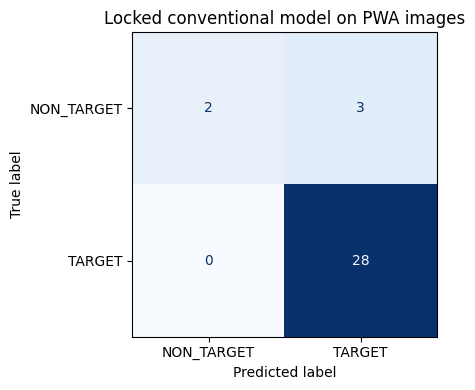

In [7]:
baseline = pwa.copy()
baseline["probability_target"] = score_model(model, baseline)
baseline["prediction_at_locked_threshold"] = (
    baseline["probability_target"] >= THRESHOLD
).astype(int)
baseline["correct"] = baseline["prediction_at_locked_threshold"].eq(baseline["binary_label"])

baseline.to_csv(RUN_DIR / "pwa_baseline_predictions.csv", index=False)
base_metrics = results(baseline)
base_metrics["sensitivity_95pct_image_level_wilson"] = wilson(base_metrics["tp"], base_metrics["target_images"])
base_metrics["specificity_95pct_image_level_wilson"] = wilson(base_metrics["tn"], base_metrics["non_target_images"])
base_metrics["note"] = (
    "These image-level ranges assume independent images; that assumption is not fully met "
    "for source-grouped PWA figures. These are not clinical confidence intervals."
)
(RUN_DIR / "pwa_baseline_metrics.json").write_text(
    json.dumps(base_metrics, indent=2) + "\n", encoding="utf-8"
)
by_diagnosis = per_group_results(baseline, "diagnosis")
by_source = per_group_results(baseline, "source_group_id")
by_diagnosis.to_csv(RUN_DIR / "pwa_baseline_by_diagnosis.csv", index=False)
by_source.to_csv(RUN_DIR / "pwa_baseline_by_source.csv", index=False)

print("Original model performance at Notebook 04's locked threshold:")
display(pd.DataFrame([base_metrics]).drop(columns=["note"]).round(3))
print("By diagnosis (missing-class metrics appear as blank/NaN, not zero):")
display(by_diagnosis.round(3))

errors = baseline.loc[~baseline["correct"], [
    "image_id", "diagnosis", "label_group", "source_id",
    "split_group_id", "probability_target", "prediction_at_locked_threshold"
]].sort_values("probability_target")
errors.to_csv(RUN_DIR / "pwa_baseline_errors.csv", index=False)
print("Misclassified images:", len(errors))
display(errors)

fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay.from_predictions(
    baseline["binary_label"], baseline["prediction_at_locked_threshold"],
    labels=[0, 1], display_labels=["NON_TARGET", "TARGET"], ax=ax,
    cmap="Blues", colorbar=False
)
ax.set_title("Locked conventional model on PWA images")
fig.tight_layout()
fig.savefig(RUN_DIR / "pwa_baseline_confusion.png", dpi=150)
plt.show()

## 6. Check the predictions and image context

An incorrect result might be caused by the lesion's appearance, image quality, cropping, or a provisional label. These pictures are **for review, not for relabelling to match the model**. If a dermatologist later corrects a label, keep a new, versioned dataset and a new run.

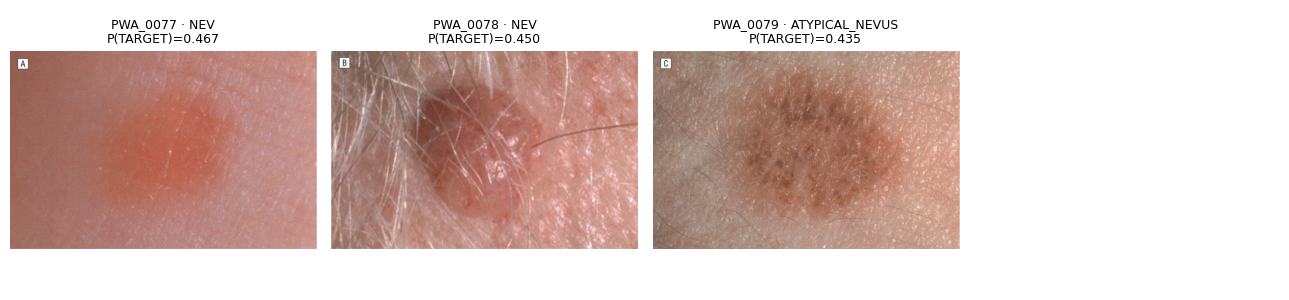

In [8]:
# Show up to 12 model mistakes, or the 12 least-confident images if no mistakes.
examples = baseline.loc[~baseline["correct"]].copy()
if examples.empty:
    examples = baseline.assign(distance=(baseline["probability_target"]-THRESHOLD).abs())
    examples = examples.nsmallest(12, "distance")
else:
    examples = examples.head(12)

if not examples.empty:
    columns = 4
    rows = math.ceil(len(examples) / columns)
    fig, axes = plt.subplots(rows, columns, figsize=(13, 3.1*rows))
    axes = np.asarray(axes).reshape(-1)
    for ax, (_, r) in zip(axes, examples.iterrows()):
        with Image.open(r["absolute_path"]) as image:
            ax.imshow(image.convert("RGB"))
        ax.set_title(
            f'{r["image_id"]} · {r["diagnosis"]}\n'
            f'P(TARGET)={r["probability_target"]:.3f}', fontsize=9
        )
        ax.axis("off")
    for ax in axes[len(examples):]:
        ax.axis("off")
    fig.tight_layout()
    fig.savefig(RUN_DIR / "pwa_prediction_review.png", dpi=140)
    plt.show()

## 7. Prepare conservative PWA adaptation (exploratory only)

**Why replay?** If we update the classifier using just a few PWA cancer photographs, it might start calling almost everything TARGET. We therefore combine each fold's PWA **training** cases with a balanced, fixed subset of ordinary-skin images from Notebook 02's **training split only**. We update **only the last Dense classifier layer**, keeping EfficientNet's visual backbone frozen.

The two PWA source groups that contain benign examples are split across the two folds, so each training fold sees *just one benign PWA source*. This is still a major weakness: a good or bad result cannot be treated as a reliable improvement. We use **fixed six epochs**, no PWA validation tuning, and the same locked threshold throughout.

In [9]:
def training_dataset(frame):
    paths = frame["absolute_path"].astype(str).to_numpy()
    labels = frame["binary_label"].to_numpy(dtype=np.float32)
    weights = frame["sample_weight"].to_numpy(dtype=np.float32)
    ds = tf.data.Dataset.from_tensor_slices((paths, labels, weights))
    ds = ds.shuffle(len(frame), seed=SEED, reshuffle_each_iteration=True)
    ds = ds.map(
        lambda path, label, weight: (decode_and_resize(path), label, weight),
        num_parallel_calls=tf.data.AUTOTUNE
    )
    return ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)


def make_replay(conventional_train, fold):
    chosen = []
    for label in [0, 1]:
        class_rows = conventional_train[conventional_train["binary_label"] == label]
        if len(class_rows) < REPLAY_PER_CLASS:
            raise ValueError(f"Not enough conventional training images for class {label}")
        chosen.append(class_rows.sample(n=REPLAY_PER_CLASS, random_state=SEED + fold + label))
    replay = pd.concat(chosen, ignore_index=True)
    replay["absolute_path"] = replay["filepath"].astype(str)
    replay["sample_weight"] = 1.0
    replay["training_origin"] = "conventional_train_replay"
    return replay


def fresh_head_only_model():
    copy = tf.keras.models.load_model(locked_model_path, compile=False)
    copy.trainable = True
    for layer in copy.layers:
        layer.trainable = (layer.name == "probability_target")
    n_trainable = int(sum(np.prod(v.shape) for v in copy.trainable_weights))
    if n_trainable == 0:
        raise RuntimeError("Failed to identify the Dense classifier head")
    if any(layer.trainable for layer in copy.layers if layer.name != "probability_target"):
        raise RuntimeError("Backbone is not frozen")
    copy.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=ADAPT_LEARNING_RATE),
        loss="binary_crossentropy",
        metrics=[tf.keras.metrics.BinaryAccuracy(name="accuracy")]
    )
    print("Trainable head parameters:", n_trainable)
    return copy


if RUN_ADAPTATION:
    if not TRAIN_PATH.is_file():
        raise FileNotFoundError(f"Missing Notebook 02 frozen training file: {TRAIN_PATH}")
    if sha256_file(TRAIN_PATH) != lock["train_sha256"]:
        raise ValueError("Conventional training manifest changed after Notebook 04")
    conventional_train = pd.read_csv(TRAIN_PATH)
    needed = {"image_id", "filepath", "binary_label", "md5_hash"}
    if not needed.issubset(conventional_train.columns):
        raise ValueError(f"Conventional training file must contain {needed}")
    if not conventional_train["binary_label"].isin([0, 1]).all():
        raise ValueError("Invalid replay labels")
    pwa_md5 = {md5_file(path) for path in pwa["absolute_path"]}
    if pwa_md5 & set(conventional_train["md5_hash"].astype(str).str.lower()):
        raise ValueError("A PWA image has the same MD5 hash as a conventional training image")
    # Exact-file hashes cannot rule out resized/cropped copies of the same photo.
    print("Conventional replay images are taken ONLY from Notebook 02's training split.")
    print("PWA / conventional overlap check: no identical file hashes found (near duplicates not excluded).")
else:
    print("RUN_ADAPTATION=False: baseline evaluation is complete; no training will run.")

Conventional replay images are taken ONLY from Notebook 02's training split.
PWA / conventional overlap check: no identical file hashes found (near duplicates not excluded).


## 8. Run two source-group-held-out experiments

For each fold: (a) set aside all images in held-out source groups; (b) load an untouched copy of the locked conventional model; (c) train its classifier head on **other PWA groups** plus conventional training replay; (d) score the held-out cases with both the original and the adapted model. Each PWA image receives exactly **one out-of-fold adapted prediction**.

We save the training manifest, training history, fold-specific model, held-out predictions, and checksums. **Never select a fold model for deployment based on its test results.**

In [10]:
fold_predictions = []
fold_summaries = []

if RUN_ADAPTATION:
    for fold in (0, 1):
        train_pwa = pwa.loc[pwa["heldout_fold"] != fold].copy()
        heldout = pwa.loc[pwa["heldout_fold"] == fold].copy()
        train_groups = set(train_pwa["split_group_id"])
        heldout_groups = set(heldout["split_group_id"])
        assert not (train_groups & heldout_groups)
        assert not (set(train_pwa["sha256"]) & set(heldout["sha256"]))
        if set(train_pwa["binary_label"]) != {0, 1} or set(heldout["binary_label"]) != {0, 1}:
            raise ValueError("Each fold must contain both target and non-target PWA images")

        fold_dir = RUN_DIR / f"fold_{fold+1}"
        fold_dir.mkdir()  # Fail rather than overwrite
        replay = make_replay(conventional_train, fold)
        train_pwa["sample_weight"] = PWA_SAMPLE_WEIGHT
        train_pwa["training_origin"] = "pwa_train_source_groups"
        combined = pd.concat([train_pwa, replay], ignore_index=True)
        combined[["image_id", "absolute_path", "binary_label", "sample_weight", "training_origin"]].to_csv(
            fold_dir / "adaptation_training_manifest.csv", index=False
        )
        heldout[["image_id", "split_group_id", "binary_label"]].to_csv(
            fold_dir / "heldout_manifest.csv", index=False
        )

        tf.keras.backend.clear_session()
        gc.collect()
        adapted = fresh_head_only_model()
        print(f"\nFold {fold+1}: {len(train_pwa)} PWA training images, {len(replay)} replay images, "
              f"{len(heldout)} PWA held-out images")
        history = adapted.fit(training_dataset(combined), epochs=ADAPT_EPOCHS, verbose=1)
        pd.DataFrame(history.history).assign(epoch=np.arange(1, ADAPT_EPOCHS+1)).to_csv(
            fold_dir / "training_history.csv", index=False
        )
        adapted_path = fold_dir / "adapted_head.keras"
        adapted.save(adapted_path)

        scores = score_model(adapted, heldout)
        pred = heldout.copy()
        pred["adapted_probability_target"] = scores
        pred["baseline_probability_target"] = pred["image_id"].map(
            baseline.set_index("image_id")["probability_target"]
        )
        if pred["baseline_probability_target"].isna().any():
            raise ValueError("Baseline and adaptation rows do not match")
        pred["baseline_prediction"] = (pred["baseline_probability_target"] >= THRESHOLD).astype(int)
        pred["adapted_prediction"] = (pred["adapted_probability_target"] >= THRESHOLD).astype(int)
        pred.to_csv(fold_dir / "heldout_predictions.csv", index=False)
        fold_predictions.append(pred)

        fold_result = {
            "heldout_fold": fold+1,
            "pwa_train_images": len(train_pwa),
            "pwa_train_non_target": int((train_pwa["binary_label"] == 0).sum()),
            "pwa_heldout_images": len(heldout),
            "pwa_heldout_non_target": int((heldout["binary_label"] == 0).sum()),
            "pwa_train_source_groups": len(train_groups),
            "heldout_source_groups": len(heldout_groups),
            "model_sha256": sha256_file(adapted_path),
            "baseline": results(pred, "baseline_probability_target"),
            "adapted": results(pred, "adapted_probability_target"),
        }
        (fold_dir / "fold_metrics.json").write_text(
            json.dumps(fold_result, indent=2) + "\n", encoding="utf-8"
        )
        fold_summaries.append(fold_result)
        print("Fold results at the original threshold:")
        display(pd.DataFrame([
            {"model": "locked_original", **fold_result["baseline"]},
            {"model": "adapted_head", **fold_result["adapted"]}
        ]).round(3))
        del adapted
        gc.collect()

    (RUN_DIR / "fold_metrics.json").write_text(
        json.dumps(fold_summaries, indent=2) + "\n", encoding="utf-8"
    )

Trainable head parameters: 1281

Fold 1: 15 PWA training images, 160 replay images, 18 PWA held-out images
Epoch 1/6
11/11 ━━━━━━━━━━━━━━━━━━━━ 86s 3s/step - accuracy: 0.8457 - loss: 0.4604
Epoch 2/6
11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 39ms/step - accuracy: 0.8286 - loss: 0.4555
Epoch 3/6
11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 30ms/step - accuracy: 0.8686 - loss: 0.4371
Epoch 4/6
11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 46ms/step - accuracy: 0.8629 - loss: 0.4514
Epoch 5/6
11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 40ms/step - accuracy: 0.8800 - loss: 0.3834
Epoch 6/6
11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 44ms/step - accuracy: 0.8514 - loss: 0.4525
Fold results at the original threshold:


,model,images,target_images,non_target_images,tp,fp,tn,fn,sensitivity,specificity,balanced_accuracy,auroc,average_precision,threshold
0,locked_original,18,14,4,14,3,1,0,1.0,0.25,0.625,0.946,0.987,0.375
1,adapted_head,18,14,4,14,3,1,0,1.0,0.25,0.625,0.946,0.987,0.375


Trainable head parameters: 1281

Fold 2: 18 PWA training images, 160 replay images, 15 PWA held-out images
Epoch 1/6
12/12 ━━━━━━━━━━━━━━━━━━━━ 22s 1s/step - accuracy: 0.8258 - loss: 0.4778
Epoch 2/6
12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 44ms/step - accuracy: 0.8652 - loss: 0.4740
Epoch 3/6
12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 45ms/step - accuracy: 0.8483 - loss: 0.4761
Epoch 4/6
12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 48ms/step - accuracy: 0.8315 - loss: 0.4950
Epoch 5/6
12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 42ms/step - accuracy: 0.9045 - loss: 0.4080
Epoch 6/6
12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 41ms/step - accuracy: 0.8652 - loss: 0.4465


Fold results at the original threshold:


,model,images,target_images,non_target_images,tp,fp,tn,fn,sensitivity,specificity,balanced_accuracy,auroc,average_precision,threshold
0,locked_original,15,14,1,14,0,1,0,1.0,1.0,1.0,1.0,1.0,0.375
1,adapted_head,15,14,1,14,0,1,0,1.0,1.0,1.0,1.0,1.0,0.375


## 9. Compare paired held-out PWA predictions

This comparison uses **the same 33 held-out images for both models**. The baseline predictions come from the locked model; the adapted predictions come from models that did not train on the image's source group. This comparison is **exploratory**: both non-target sources are tiny, labels are provisional, and the folds are not a new independent external test set.

A lower number of false negatives may be good for a screening study, but **more false positives** matter too. Do not choose a new threshold based on this chart.

,model,images,target_images,non_target_images,tp,fp,tn,fn,sensitivity,specificity,balanced_accuracy,auroc,average_precision,threshold
0,Locked conventional,33,28,5,28,3,2,0,1.0,0.4,0.7,0.979,0.997,0.375
1,Exploratory PWA-adapted (out-of-fold),33,28,5,28,3,2,0,1.0,0.4,0.7,0.979,0.997,0.375


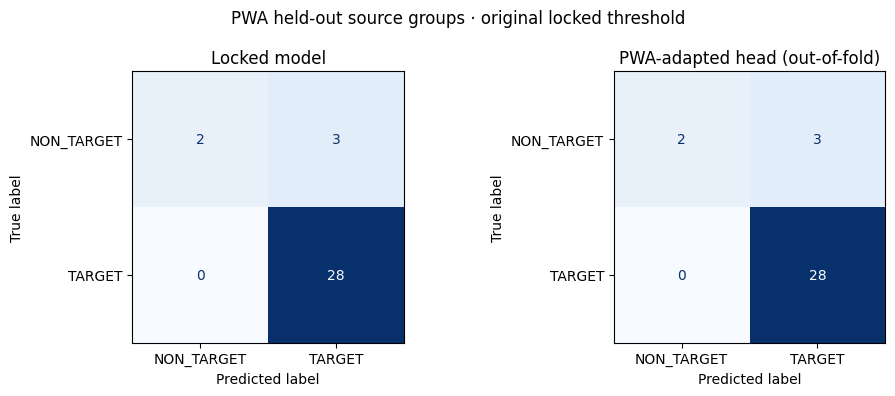

Change in true positives: 0
Change in false positives: 0
REMINDER: This is not proof the adapted model generalizes to new PWA patients.


In [11]:
if RUN_ADAPTATION:
    paired = pd.concat(fold_predictions, ignore_index=True)
    if len(paired) != len(pwa) or paired["image_id"].duplicated().any():
        raise ValueError("Every PWA image must have exactly one held-out prediction")
    if set(paired["image_id"]) != set(pwa["image_id"]):
        raise ValueError("Missing or unexpected PWA predictions")
    paired = paired.sort_values("image_id").reset_index(drop=True)
    paired.to_csv(RUN_DIR / "pwa_paired_out_of_fold_predictions.csv", index=False)

    initial = results(paired, "baseline_probability_target")
    adapted = results(paired, "adapted_probability_target")
    comparison = pd.DataFrame([
        {"model": "Locked conventional", **initial},
        {"model": "Exploratory PWA-adapted (out-of-fold)", **adapted},
    ])
    comparison.to_csv(RUN_DIR / "pwa_paired_comparison.csv", index=False)
    display(comparison.round(3))

    diagnosis_rows = []
    for name, grp in paired.groupby("diagnosis"):
        for model_name, col in [
            ("locked", "baseline_probability_target"),
            ("adapted", "adapted_probability_target")
        ]:
            diagnosis_rows.append({"diagnosis": name, "model": model_name, **results(grp, col)})
    pd.DataFrame(diagnosis_rows).to_csv(RUN_DIR / "pwa_paired_by_diagnosis.csv", index=False)

    fig, axs = plt.subplots(1, 2, figsize=(10, 4))
    for ax, col, title in zip(
        axs, ["baseline_probability_target", "adapted_probability_target"],
        ["Locked model", "PWA-adapted head (out-of-fold)"]
    ):
        ConfusionMatrixDisplay.from_predictions(
            paired["binary_label"], (paired[col] >= THRESHOLD).astype(int),
            labels=[0, 1], display_labels=["NON_TARGET", "TARGET"],
            cmap="Blues", colorbar=False, ax=ax
        )
        ax.set_title(title)
    fig.suptitle("PWA held-out source groups · original locked threshold")
    fig.tight_layout()
    fig.savefig(RUN_DIR / "pwa_paired_confusion.png", dpi=150)
    plt.show()

    print("Change in true positives:", adapted["tp"] - initial["tp"])
    print("Change in false positives:", adapted["fp"] - initial["fp"])
    print("REMINDER: This is not proof the adapted model generalizes to new PWA patients.")
else:
    print("No adaptation comparison: RUN_ADAPTATION is False.")

## 10. Record the limitations and saved files

Interpret these numbers as an **early technical experiment**, not evidence for clinical use. We have no verified AK cases, only two source groups of benign lesions, source-reported labels, images at different sizes, and unknown patient overlap for some sources. Sensitivity and specificity estimates can vary greatly when a single image changes classification. Further dermatologist review and **new independent PWA cases** are needed before claiming a reliable improvement or choosing a deployed model.

The original Notebook 04 checkpoint and threshold are **never modified**. An adapted fold checkpoint is a research artifact only. To build a deployable PWA model later, define a new training plan and protect a genuinely unseen clinical test set before training.

In [12]:
summary = {
    "dataset_images": len(pwa),
    "pwa_source_groups": int(pwa["split_group_id"].nunique()),
    "target_images": int((pwa["binary_label"] == 1).sum()),
    "non_target_images": int((pwa["binary_label"] == 0).sum()),
    "baseline": base_metrics,
    "adaptation_ran": bool(RUN_ADAPTATION),
    "limitations": [
        "Source-reported diagnoses; no independent dermatologist label confirmation for every image.",
        "Only five PWA non-target images from two source groups; atypical nevi are not normal skin.",
        "No PWA actinic keratosis images in this dataset.",
        "Published-source groups are a proxy for patient identity, not verified independent patients.",
        "Some sources include multiple images or views of the same case.",
        "Image-level Wilson intervals do not account for source/patient clustering.",
        "A two-fold pilot adaptation is exploratory and not a reliable clinical generalization estimate.",
        "The original threshold remains fixed; no model is approved for clinical diagnosis or referral automation."
    ],
}
if RUN_ADAPTATION:
    summary["paired_out_of_fold"] = {
        "locked_original": initial,
        "exploratory_pwa_adapted": adapted
    }
(RUN_DIR / "experiment_summary.json").write_text(
    json.dumps(summary, indent=2) + "\n", encoding="utf-8"
)

print("Done. Files saved under:", RUN_DIR)
for file in sorted(RUN_DIR.rglob("*")):
    if file.is_file():
        print("-", file.relative_to(RUN_DIR))
print("\nKeep Notebook 04's locked model and threshold unchanged.")
print("Do not treat the adapted fold checkpoints as a final model.")

Done. Files saved under: /content/drive/MyDrive/SkinX/models/runs/notebook_05/pwa_grouped_v1
- experiment_summary.json
- fold_1/adaptation_training_manifest.csv
- fold_1/adapted_head.keras
- fold_1/fold_metrics.json
- fold_1/heldout_manifest.csv
- fold_1/heldout_predictions.csv
- fold_1/training_history.csv
- fold_2/adaptation_training_manifest.csv
- fold_2/adapted_head.keras
- fold_2/fold_metrics.json
- fold_2/heldout_manifest.csv
- fold_2/heldout_predictions.csv
- fold_2/training_history.csv
- fold_metrics.json
- pwa_baseline_by_diagnosis.csv
- pwa_baseline_by_source.csv
- pwa_baseline_confusion.png
- pwa_baseline_errors.csv
- pwa_baseline_metrics.json
- pwa_baseline_predictions.csv
- pwa_fixed_group_plan.csv
- pwa_paired_by_diagnosis.csv
- pwa_paired_comparison.csv
- pwa_paired_confusion.png
- pwa_paired_out_of_fold_predictions.csv
- pwa_prediction_review.png
- settings.json

Keep Notebook 04's locked model and threshold unchanged.
Do not treat the adapted fold checkpoints as a fina